In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

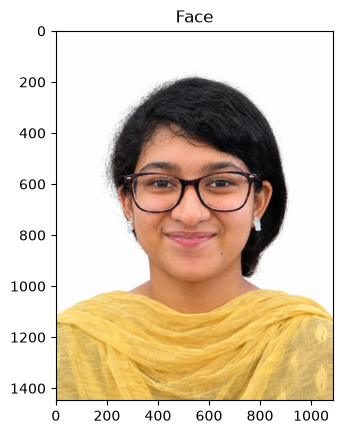

In [2]:
# Load the Face Image
faceImage = cv2.imread('3E108C11-46EF-4E1E-A24B-ECB3E19B3DCA.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(1448, 1086, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(1448, 1086, 3)

Text(0.5, 1.0, 'glassPNG')

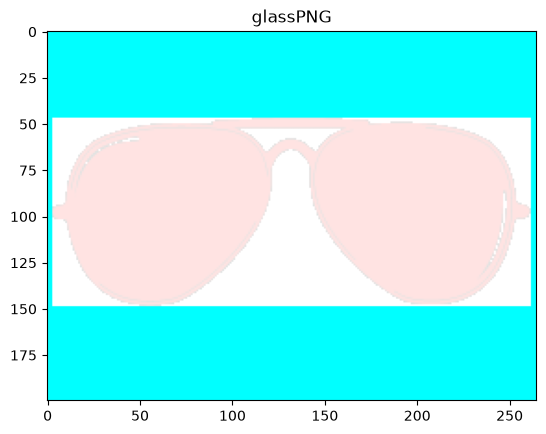

In [5]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass-png-aviator-20sunglasses-20png-265.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [21]:
# Resize the sunglasses to better match the width and height of her actual glasses
glassPNG = cv2.resize(glassPNG, (670, 200))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(200, 670, 4)


In [22]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

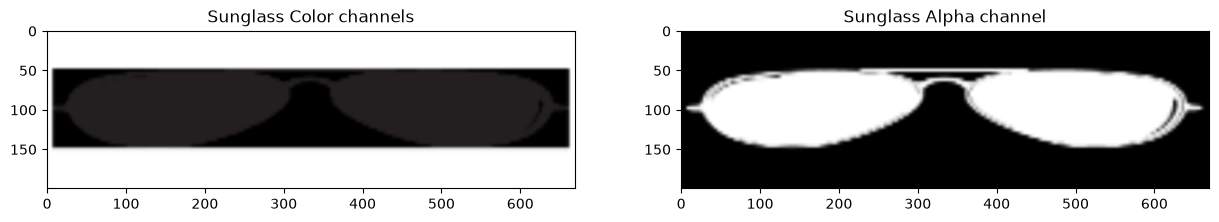

In [23]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

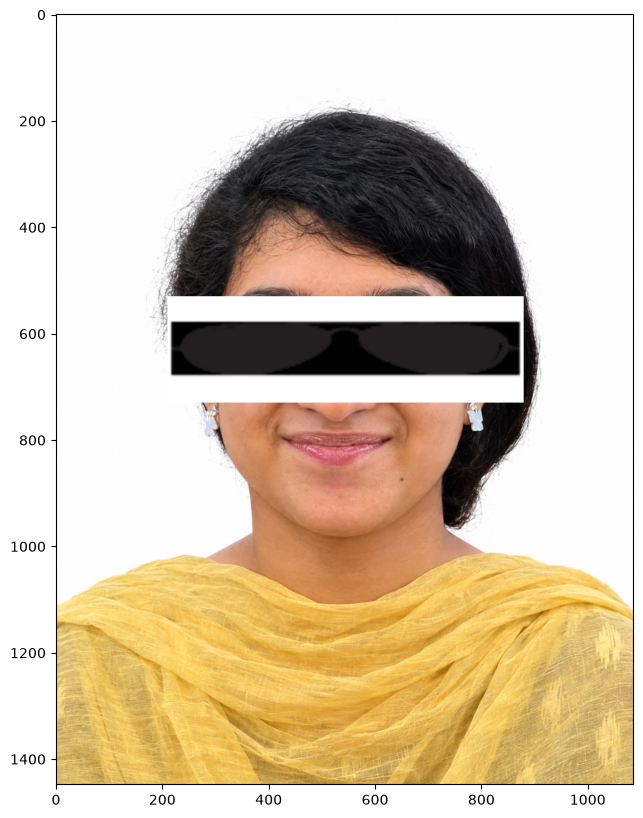

In [24]:
# Make a copy
#faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive = faceImage.copy()

# Replace the eye region with the sunglass image
faceWithGlassesNaive[530:730, 210:880]=glassBGR
plt.figure(figsize = [10, 10])


plt.imshow(faceWithGlassesNaive[...,::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

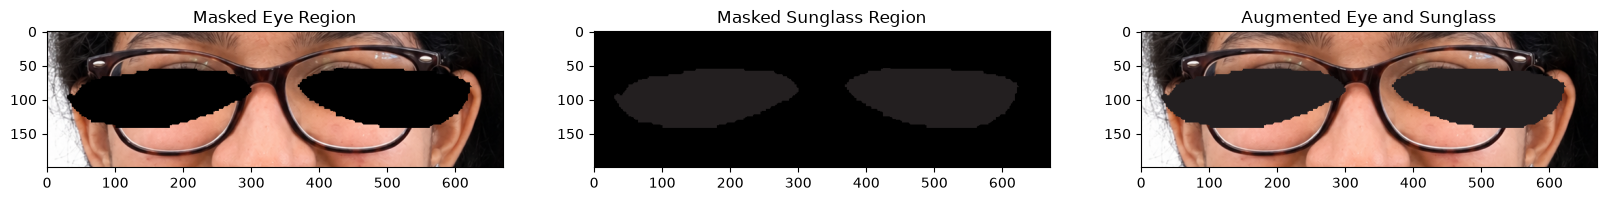

In [25]:
# Make the dimensions of the mask same as the input image.
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1)) 

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask / 255) 

# Make a copy
faceWithGlassesArithmetic = faceImage.copy() 

# Get the eye region from the face image using the correct bounding box
eyeROI = faceWithGlassesArithmetic[530:730, 210:880] 

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask)) 

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR, glassMask) 

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass) 

# Display the intermediate results
plt.figure(figsize = [20, 20])
plt.subplot(131); plt.imshow(maskedEye[..., ::-1]); plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass[..., ::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[..., ::-1]); plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

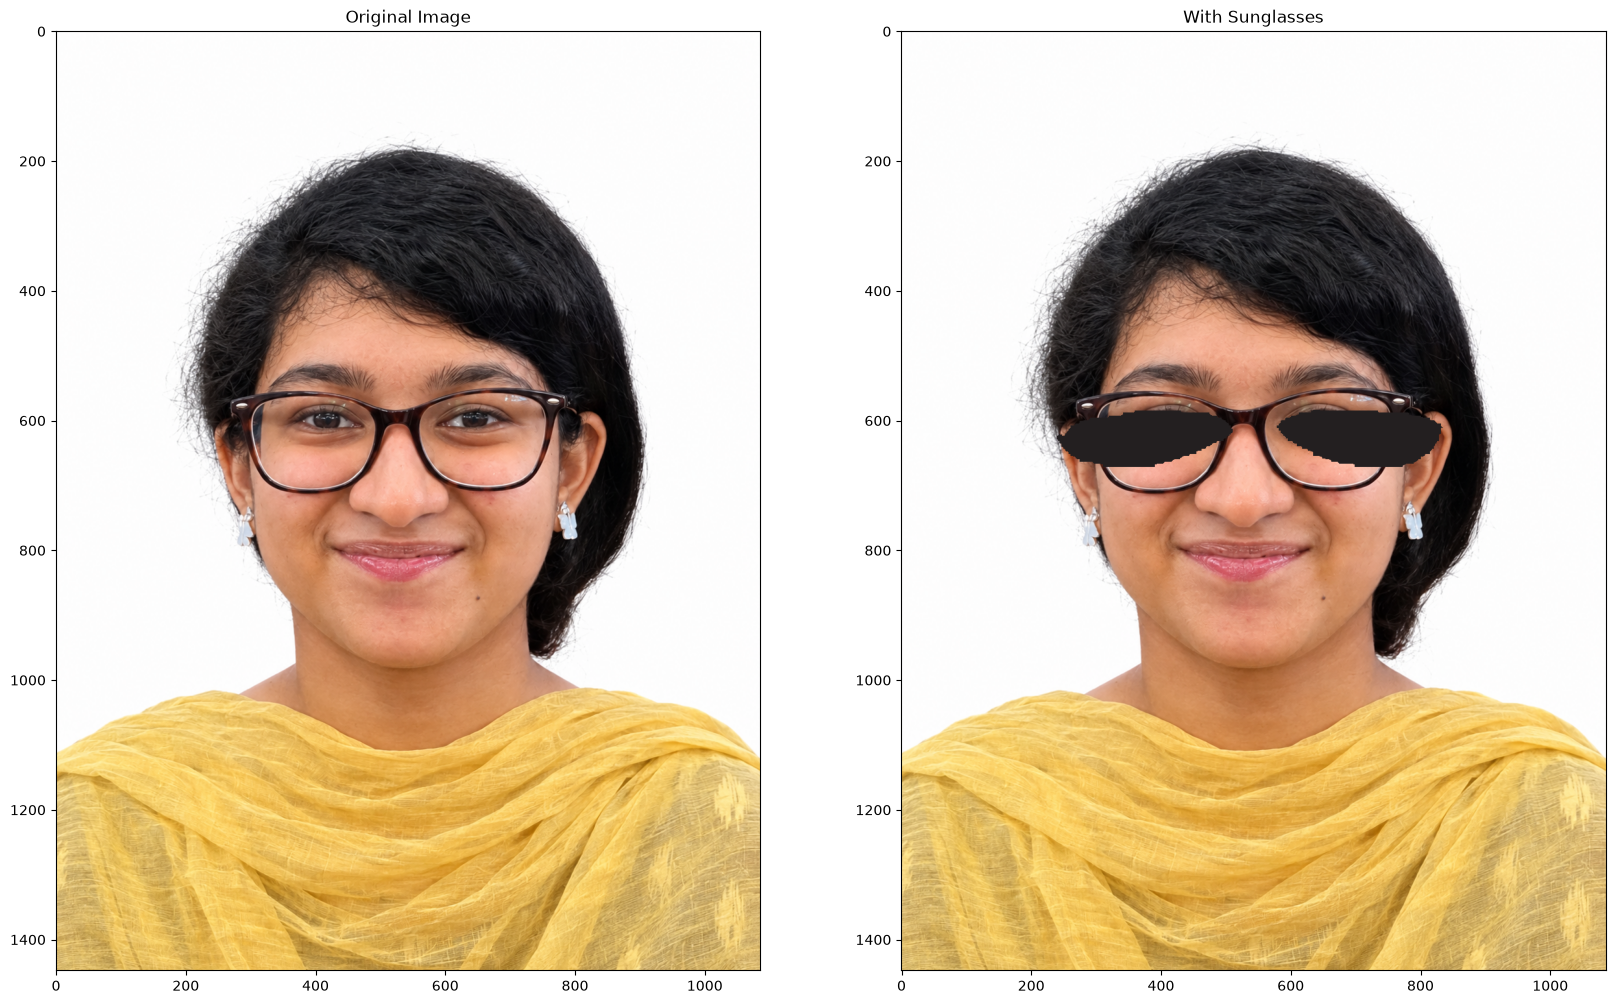

In [26]:
# Replace the eye ROI with the output from the previous section
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[530:730, 210:880] = eyeRoiFinal 

# Display the final result
plt.figure(figsize = [20, 20])
plt.subplot(121); plt.imshow(faceImage[:, :, ::-1]); plt.title("Original Image")
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:, :, ::-1]); plt.title("With Sunglasses")